In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Torch version: {torch.__version__}")
print(f"Using device: {device}")

Torch version: 2.14.1+cu132
Using device: cuda


In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM, ViTModel, ViTImageProcessor
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

In [8]:
from datasets import load_dataset
from PIL import Image
import requests
from io import BytesIO
import warnings
warnings.filterwarnings('ignore')

# Vision Encoders
- Vision encoder converts image into feature vectors.
- These feature vectors are used to pre-train Vision Transformer [ViT]
The Steps are as follows:
1. Splits image into 16x16 patches
2. Projects the patches into embeddings
3. Process patches through transformers layers
4. Outputs feature vectors (One per Patch + CLS token)

Calculation 224 x 224 image with 16 x 16 patches ->
* (224 / 16) x (224 / 16) = 14 x 14 = 196 patches
* 196 + 1 = 197 tokens 
* Each tokens has dimensions 1024

In [9]:
vision_model_name = "google/vit-base-patch16-224-in21k"
vision_model = ViTModel.from_pretrained(vision_model_name).to(device)
img_processor = ViTImageProcessor.from_pretrained(vision_model_name)

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 8502.20it/s]


In [12]:
for param in vision_model.parameters():
    param.requires_grad = False

vision_model.eval()
print(f"Vision Model hidden size : {vision_model.config.hidden_size}")
print(f"Number of patches : {(224//16)**2} + 1 CLS Token = {(224//16)**2 + 1}")

Vision Model hidden size : 768
Number of patches : 196 + 1 CLS Token = 197


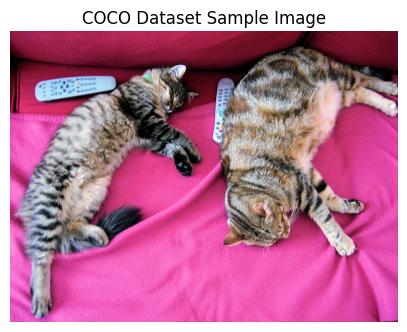

In [13]:
url = "http://images.cocodataset.org/val2017/000000039769.jpg"
response = requests.get(url)
sample_img = Image.open(BytesIO(response.content))
plt.figure(figsize=(5, 5))
plt.imshow(sample_img)
plt.axis('off')
plt.title("COCO Dataset Sample Image")
plt.show()